In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
%pip install langchain langchain-core langchain-openai langchain-anthropic -q
import os
if os.path.exists("requirements.txt"):
    %pip install -r requirements.txt -q
else:
    print("requirements.txt not found -- skipping")



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\Provat\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


"??  requirements.txt not found - skipping"


'test' is not recognized as an internal or external command,
operable program or batch file.


In [3]:
%pip install langchain-ollama -q


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\Provat\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
# ======================================================================
# COMPANY PROFILE -- the only company-specific part of this notebook.
# The analysts, debate, trader, risk and verifier code is shared by every international notebook: raem_analysts/international/
# To change a company-specific value (ticker, log name, peer list, sector text), edit it here.
# ======================================================================
COMPANY = "2222.SR"
RAEM_PROFILE = {
    "group": "international",
    "TICKER": "2222.SR",
    "LOG": "ARAMCO",
    "FILE": "2222_SR",
    "slots": {
        "graph_analyst.1": [
            "    # Tadawul large / liquid names (symbols from memory; any that return <60 rows are dropped automatically)",
            "    \"1120.SR\", \"1180.SR\", \"1150.SR\", \"1010.SR\", \"1060.SR\", \"1140.SR\", \"1211.SR\", \"1111.SR\",",
            "    \"2010.SR\", \"2020.SR\", \"2060.SR\", \"2080.SR\", \"2222.SR\", \"2280.SR\", \"2290.SR\", \"2310.SR\", \"2350.SR\", \"2380.SR\",",
            "    \"4002.SR\", \"4003.SR\", \"4013.SR\", \"4030.SR\", \"4190.SR\", \"4200.SR\", \"4300.SR\",",
            "    \"5110.SR\", \"7010.SR\", \"7020.SR\", \"7030.SR\", \"7202.SR\", \"8010.SR\", \"8210.SR\", \"1303.SR\", \"3040.SR\", \"3050.SR\", \"3060.SR\","
        ],
        "forecasting_agent.1": [
            "#   4) Writes every candidate's h=1..10 predictions to forecast_log/2222.SR_forecasts.csv (same schema as AAPL_forecasts.csv)"
        ]
    }
}

import os, sys
sys.path.insert(0, os.getcwd())   # raem_analysts/ sits next to the notebooks
from raem_analysts import use_shared

In [ ]:
# Llm Setup And Logger -- shared code: raem_analysts/international/llm_setup_and_logger.py
use_shared("llm_setup_and_logger")

In [5]:
import sys, os

# ✅ FIXED: no more hardcoded Windows path (was C:\Users\Nura\...).
# Reads from env var TRADINGAGENTS_PATH if set, else falls back to a
# relative './TradingAgents' folder next to this notebook — works on
# Windows/Linux/Kaggle alike.
TRADING_AGENTS_PATH = os.environ.get(
    "TRADINGAGENTS_PATH",
    os.path.join(os.getcwd(), "TradingAgents"),
)

if TRADING_AGENTS_PATH not in sys.path:
    sys.path.append(TRADING_AGENTS_PATH)

if not os.path.isdir(TRADING_AGENTS_PATH):
    print(f"⚠️  Path does not exist: {TRADING_AGENTS_PATH}")
    print("    Set TRADINGAGENTS_PATH env var to your local TradingAgents checkout.")
else:
    print("✅ Path added:", TRADING_AGENTS_PATH)


⚠️  Path does not exist: c:\Users\Provat\Downloads\predict-final\notebooks\TradingAgents
    Set TRADINGAGENTS_PATH env var to your local TradingAgents checkout.


## 🧠 ChromaDB Memory Setup (RAEM Episodic Memory + News RAG)

In [6]:
# Chromadb Memory Setup -- shared code: raem_analysts/international/chromadb_memory_setup.py
use_shared("chromadb_memory_setup")

✅ ChromaDB ready at: ./raem_chroma_db
   📦 episodic_memory  : 4 episodes stored
   📰 news_corpus      : 51 chunks stored
✅ Regime classifier + ID helper ready!
Chroma retry helper ready (guards against transient concurrent-access errors)!


## 📈 Outcome Backfill — পুরোনো PENDING episodes-এ আজকের price দিয়ে P&L আপডেট

In [7]:
# Outcome Backfill -- shared code: raem_analysts/international/outcome_backfill.py
use_shared("outcome_backfill")

📈 OUTCOME BACKFILL — পুরোনো episode-এ P&L আপডেট
   ℹ️  কোনো PENDING episode নেই — backfill করার কিছু নেই।
   মোট resolve হলো: 0 episode



In [8]:
import os
os.environ["TRADINGAGENTS_LLM_PROVIDER"] = "ollama"
print("✅ Config ready!")

✅ Config ready!


## 📡 Market-data shim (yfinance) for the v11 price-based cells

The v11 cells (10-day scenario, peer-graph analyst, forecasting agent, position sizing) were written for the DSE and call
`fetch_dse_ohlcv_range()` / `fetch_dse_company_snapshot()`. This notebook trades a yfinance ticker, so the same two names are
defined here on top of yfinance and return the same shapes (Date-indexed Open/High/Low/Close/Volume, ascending; `{"Sector": ...}`).
Nothing else in the v11 cells needed to change.

In [ ]:
# Market Data Shim -- shared code: raem_analysts/international/market_data_shim.py
use_shared("market_data_shim")

## 🛡️ Fact Guard — handoff-level hallucination check on every LLM call

Each agent's output is checked in code before the next agent reads it: numbers must come from the agent's own input, and known label/direction errors (SMA support vs resistance, N/A cited as 0%, TTM mislabel, missing data read as neutral) trigger one re-ask. Set `GUARD_ENABLED = False` to turn it off.

In [ ]:
# Fact Guard -- shared code: raem_analysts/international/fact_guard.py
use_shared("fact_guard")

In [9]:
# Fundamentals Analyst -- shared code: raem_analysts/international/fundamentals_analyst.py
use_shared("fundamentals_analyst")

📊 Fetching fundamentals data for 2222.SR on 2026-10-03...
⚙️  Calling: get_fundamentals
   ✅ Got 722 chars
⚙️  Calling: get_balance_sheet
   ✅ Got 7009 chars
⚙️  Calling: get_cashflow
   ✅ Got 4098 chars
⚙️  Calling: get_income_statement
   ✅ Got 4171 chars
✅ Fundamentals Report ready!
📝 Logged: Fundamentals Analyst  (sessions stored: 3)


# Fundamental Analysis Report for 2222.SR as of 2026-10-03

## Company Overview
**Company Name:** 2222.SR  
**Sector:** Energy (Oil & Gas Integrated)  
**Exchange:** Tadawul (Saudi Exchange)

## Profitability
- **Net Income (TTM):** $121.51B
- **Revenue (TTM):** $1823.48B
- **Gross Profit (N/A):** Data not available  
- **Operating Income:** $216.15B
- **EBITDA:** $245.18B

The company has a strong operating performance, with an EBITDA of $245.18B and net income of $121.51B for the trailing twelve months (TTM). The gross profit is not available in this data set.

## Balance Sheet
- **Total Debt:** $355.24B  
- **Net Debt:** $126.32B

The company has significant debt, with total debt of $355.24B and net debt of $126.32B. This indicates a substantial financial leverage.

## Cash Flow
- **Free Cash Flow (Q):** $45.98B  
- **Stock Buybacks:** ($2.03B)

The company generated free cash flow of $45.98B in the most recent quarter, which is positive but slightly offset by stock buybacks worth $2.03B.

## Risks
1. High Debt Levels: The significant debt levels could pose a risk to financial stability.
2. Market Volatility: Energy companies are often affected by global market fluctuations and geopolitical events.
3. Regulatory Changes: Potential changes in energy policies or regulations may impact the company's operations and profitability.

## Outlook
- **Market Cap:** $6115.42B  
- **P/E Ratio (TTM):** 14.95858  
- **EPS (TTM):** $1.69  
- **Dividend Yield:** 5.37%  
- **50-Day SMA:** $26.1716
- **52-Week Range:** $23.29 - $27.96

The company has a relatively low P/E ratio of 14.95858, suggesting that the stock may be undervalued compared to its earnings. The dividend yield is also attractive at 5.37%. However, given the high debt levels and potential market risks, investors should exercise caution.

### Summary Table
| Metric                | Value                          |
|-----------------------|-------------------------------|
| Market Cap            | $6115.42B                     |
| P/E Ratio             | 14.95858                      |
| EPS (TTM)             | $1.69                         |
| Revenue (TTM)         | $1823.48B                     |
| Beta                  | 0.006                         |
| Dividend Yield        | 5.37%                         |
| Free Cash Flow (Q)    | $45.98B                       |
| Net Debt              | $126.32B                      |
| Total Debt            | $355.24B                      |

### Final Transaction Proposal
**BUY**

The company's strong operating performance, attractive dividend yield, and undervalued stock price make it a potentially good investment despite the high debt levels. However, investors should monitor market conditions and regulatory changes closely.

In [ ]:
# Market Analyst -- shared code: raem_analysts/international/market_analyst.py
use_shared("market_analyst")

## 🌍 Macro Regime Analyst — Market-Wide Risk Regime (VIX / Yields / DXY)

In [11]:
# Macro Regime Analyst -- shared code: raem_analysts/international/macro_regime_analyst.py
use_shared("macro_regime_analyst")


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\Provat\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


🌍 Fetching macro snapshot for 2026-10-03...


C:\Users\Provat\AppData\Local\Temp\ipykernel_8824\1703823238.py:45: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  latest = float(df["Close"].iloc[-1])
C:\Users\Provat\AppData\Local\Temp\ipykernel_8824\1703823238.py:46: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  avg = float(df["Close"].mean())
C:\Users\Provat\AppData\Local\Temp\ipykernel_8824\1703823238.py:45: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  latest = float(df["Close"].iloc[-1])
C:\Users\Provat\AppData\Local\Temp\ipykernel_8824\1703823238.py:46: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  avg = float(df["Close"].mean())
C:\Users\P

   VIX: {'latest': 15.31, 'avg': 15.78}  |  10Y: {'latest': 5.28, 'avg': 5.03}  |  DXY: {'latest': 101.93, 'avg': 100.3}
   🏷️  Macro regime: RATES_RISING
✅ Macro Regime Report ready!
📝 Logged: Macro Regime Analyst  (sessions stored: 3)


As of October 3, 2026, the VIX is slightly below its 30-day average at 15.31 compared to 15.78, suggesting a relatively calm market environment and risk-on sentiment. The 10Y Treasury Yield has risen to 5.28%, above its 30-day average of 5.03%, indicating an ongoing trend of rising interest rates. Given the RATES_RISING macro regime tag, equity markets are likely to face some headwinds but may still benefit from risk-on sentiment in a moderate environment.

In [12]:
# News Analyst -- shared code: raem_analysts/international/news_analyst.py
use_shared("news_analyst")

📰 Fetching news for 2222.SR on 2026-10-03...
⚙️  Calling: get_news
   ✅ Got 25 chars
⚙️  Calling: get_global_news
   ✅ Got 2000 chars
✅ News Report ready!
📝 Logged: News Analyst  (sessions stored: 3)


## News Analysis Report for 2222.SR - October 3, 2026

### Company News Summary:
No specific news related to 2222.SR was found.

### Global Macro Trends:
- **Stock Market Rally:** The Dow, S&P 500, and Nasdaq experienced a rally today as fears of further Federal Reserve rate hikes diminished. This positive sentiment could spill over into other markets.
- **Tech Sector Expansion in AI:** More than half of CFOs are expanding their strategies to include artificial intelligence (AI), indicating strong growth potential for tech companies.

### Sentiment Assessment:
The overall market trend is positive, with a focus on the technology sector and its expansion into advanced technologies like AI. This could have a neutral impact on 2222.SR if it operates in or closely related to these sectors.

### Key Risks:
- **Interest Rate Hikes:** Although fears of further hikes are fading, any unexpected changes can still affect market sentiment.
- **AI and Tech Competition:** The expansion into AI by CFOs could pose competitive risks for 2222.SR if it is not actively investing in these areas.

---

| Category       | Headline                                                                                         | Sentiment   | Impact     | Source                                      |
|----------------|--------------------------------------------------------------------------------------------------|-------------|------------|----------------------------------------------|
| Company News   | No news found for 2222.SR                                                                       | NEUTRAL     | NEUTRAL    | -                                            |
| Global Market  | Stock market today: Dow, S&P 500, Nasdaq rally as Fed rate-hike expectations fade                 | POSITIVE    | POSITIVE   | Yahoo Finance                                |
| Global Market  | More than 6 out of 10 CFOs expand into AI, tech strategy                                         | NEUTRAL     | NEUTRAL    | CFO Dive                                    |
| Key Risks      | Interest Rate Hikes                                                                             | NEGATIVE    | MEDIUM     | -                                            |
| Key Risks      | Expansion in AI and Tech Strategy                                                                | NEGATIVE    | HIGH       | -                                            |

This table summarizes the key points from the analysis.

## 📰 News RAG — Chunk & Store in ChromaDB

In [13]:
# News Rag -- shared code: raem_analysts/international/news_rag.py
use_shared("news_rag")

📰 Ingested 6 news chunks for 2222.SR | 2026-10-03
   Total chunks in news_corpus: 57

🔍 NEWS RAG RETRIEVAL — building context for downstream agents

📄 Source: company_news | Date: 2026-10-03 | Distance: 0.323
   No news found for 2222.SR...

📄 Source: global_news | Date: 2026-10-03 | Distance: 0.356
   ## Global Market News, from 2026-09-26 to 2026-10-03:

### Stock market today: Dow, S&P 500, Nasdaq rally as Fed rate-hike expectations fade, tech gains (source: Yahoo Finance)
Link: https://finance.yahoo.com/markets/live/stock-market-today-friday-oc...

📄 Source: global_news | Date: 2026-10-03 | Distance: 0.402
   //finance.yahoo.com/markets/stocks/articles/guidance-raise-momentum-dell-stock-130544088.html

### Aya Gold & Silver Targets Boumadine Build as Zgounder Ramps Up (source: MarketBeat)
Link: https://fin...

📄 Source: global_news | Date: 2026-10-03 | Distance: 0.411
   ss, Treasury yields ease: AlphaCheck (source: Yahoo Finance)
Link: https://finance.yahoo.com/markets/article/tec

In [14]:
# Sentiment Analyst -- shared code: raem_analysts/international/sentiment_analyst.py
use_shared("sentiment_analyst")

⚠️  get_stock_news_sentiment not found
⚠️  get_reddit_news not found
⚠️  get_reddit_global_news not found
⚠️  get_news_sentiment not found

Available sentiment tools: []
📊 Fetching sentiment data for 2222.SR on 2026-10-03...
✅ Sentiment Report ready!
📝 Logged: Sentiment Analyst  (sessions stored: 3)


## Data Source Review

For the analysis of 2222.SR's market sentiment on October 3, 2026, we relied solely on a news report that provided context for broader market trends. There was no specific company-related news available.

## Score Breakdown

- **Sentiment:** Neutral
- **Score (1-10):** 5
- **Confidence:** Moderate
- **Key Signal:** Market rally and tech sector expansion, but no direct impact on 2222.SR as of the report date.

## Key Signals

The key signals from today's news context include:
- A positive market trend with a focus on technology sectors.
- Expansion in AI strategies by CFOs indicating strong growth potential for related companies.
- Potential risks such as interest rate hikes and competition in the tech sector, but no specific impact noted for 2222.SR.

## Confidence Assessment

The confidence level is moderate due to the lack of direct company-specific news. The overall market trend provides a general sentiment that could influence 2222.SR if it operates within relevant sectors.

| Source | Sentiment | Score (1-10) | Confidence | Key Signal |
|--------|----------|--------------|------------|------------|
| News Report | Neutral | 5 | Moderate | Market rally and tech sector expansion, but no direct impact on 2222.SR as of the report date. |

## 🕸️ Graph Analyst — Peer Graph + GAT (adapted from BlindTrade)

Builds a sector + correlation graph over DSE peers, computes neighbor-aggregated features for the target stock, and trains a small GAT walk-forward. The GAT score is passed to the debaters **only if its holdout rank-IC > 0** (validate-before-deploy). Output `graph_context` is picked up by `format_hard_indicators()` in the next cell.

In [ ]:
# Graph Analyst -- shared code: raem_analysts/international/graph_analyst.py
use_shared("graph_analyst")

## 🕸️ Graph-linked news + peer-graph retrieval
Rule-based knowledge graph over `news_corpus` (NEWS → TICKER / TOPIC / REG edges). Uses `graph_result` peers, adds sector / regulator / macro news (tariffs, Fed, OPEC, antitrust...) and peers' news to `news_rag_context`. Switch: `USE_NEWS_GRAPH`.

## 👥🧬 Graph-RAG extensions (v4)
Two cells run **before** the news-graph cell: (1) peer-stock price episodes (regime → forward return) stored in `episodic_memory`, so the peer-episode hop has data; (2) LLM entity/relation extraction (Qwen2.5:7b, JSON mode, grounded in code, disk-cached) that adds entity/relation edges to the news graph. Ablation switches: `USE_PEER_EPISODES`, `USE_LLM_GRAPH`.

In [ ]:
# Peer Episodes -- shared code: raem_analysts/international/peer_episodes.py
use_shared("peer_episodes")

In [ ]:
# Llm Graph Extraction -- shared code: raem_analysts/international/llm_graph_extraction.py
use_shared("llm_graph_extraction")

In [ ]:
# Graph News -- shared code: raem_analysts/international/graph_news.py
use_shared("graph_news")

## 🔮 Forecasting Agent (validated 10-day price forecast)

Code-only agent: purged walk-forward validation of naive / damped-trend / ridge / analog-kNN. A model is used only if it beats the naive baseline on a holdout (MAE, t-stat, direction gate); otherwise the agent reports **no forecast skill** and only a historical-error range. Result is injected into the FACT SHEET and logged to `forecast_log/2222.SR_forecasts.csv` (same schema as the other forecast logs).

In [ ]:
# Forecasting Agent -- shared code: raem_analysts/international/forecasting_agent.py
use_shared("forecasting_agent")

In [ ]:
# Hard Data Helper -- shared code: raem_analysts/international/hard_data_helper.py
use_shared("hard_data_helper")

In [ ]:
# Bear Researcher -- shared code: raem_analysts/international/bear_researcher.py
use_shared("bear_researcher")

In [ ]:
# Bull Researcher -- shared code: raem_analysts/international/bull_researcher.py
use_shared("bull_researcher")

In [ ]:
# Investment Facilitator -- shared code: raem_analysts/international/investment_facilitator.py
use_shared("investment_facilitator")

In [19]:
# Investment Debate Facilitator -- shared code: raem_analysts/international/investment_debate_facilitator.py
use_shared("investment_debate_facilitator")

⚖️  INVESTMENT DEBATE FACILITATOR DECISION
### Scoring

1. **Bull Analyst Evidence Count**:
   - RSI value of 36.6599 indicating an oversold condition.
   - MACD at -0.2041 suggesting a bearish trend but not necessarily strong downward momentum.
   - Close price near the 50-day SMA ($26.0361).
   - Bollinger Bands with prices close to lower bound, suggesting potential for recovery.

2. **Bear Analyst Evidence Count**:
   - RSI value of 36.6599 indicating an oversold condition.
   - MACD at -0.2041 showing a bearish trend but not necessarily strong downward momentum.
   - Close price near the 50-day SMA ($26.0361).
   - Bollinger Bands with prices close to lower bound, suggesting potential for recovery.

**Total Specific Numbers Cited:**
- **Bull**: 4 specific numbers
- **Bear**: 4 specific numbers

### Evaluation of HARD FACT:
The HARD FACT provided is that the final transaction proposal is "BUY." According to the scoring rubric, if the HARD FACT is BUY and Bull cannot cite at least tw

## 🔁 Retrieve Similar Past Episodes (for Trader memory injection)

## 🔄 Regime-Transition Reflection — regime বদলালে আগের regime থেকে শেখা

In [ ]:
# Regime Transition Reflection -- shared code: raem_analysts/international/regime_transition_reflection.py
use_shared("regime_transition_reflection")

## 🧾 Post-Mortem / Self-Critique Agent — Cross-Regime Lessons Learned

In [ ]:
# Post Mortem Agent -- shared code: raem_analysts/international/post_mortem_agent.py
use_shared("post_mortem_agent")

## 🕸️ Graph Memory — graph-RAG over episodic memory


In [ ]:
# Graph Memory -- shared code: raem_analysts/international/graph_memory.py
use_shared("graph_memory")

In [ ]:
# Retrieve Past Episodes -- shared code: raem_analysts/international/retrieve_past_episodes.py
use_shared("retrieve_past_episodes")

In [ ]:
# Trader -- shared code: raem_analysts/international/trader.py
use_shared("trader")

In [ ]:
# Aggressive Debator -- shared code: raem_analysts/international/aggressive_debator.py
use_shared("aggressive_debator")

In [ ]:
# Conservative Debator -- shared code: raem_analysts/international/conservative_debator.py
use_shared("conservative_debator")

In [ ]:
# Neutral Debator -- shared code: raem_analysts/international/neutral_debator.py
use_shared("neutral_debator")

In [ ]:
# Risk Debate -- shared code: raem_analysts/international/risk_debate.py
use_shared("risk_debate")

In [ ]:
# Risk Facilitator -- shared code: raem_analysts/international/risk_facilitator.py
use_shared("risk_facilitator")

In [ ]:
# Portfolio Manager -- shared code: raem_analysts/international/portfolio_manager.py
use_shared("portfolio_manager")

In [ ]:
# Portfolio Manager Decision -- shared code: raem_analysts/international/portfolio_manager_decision.py
use_shared("portfolio_manager_decision")

## 📈 Prediction Engine — Quantitative 5-Day Price Forecast


In [31]:
# Prediction Engine -- shared code: raem_analysts/international/prediction_engine.py
use_shared("prediction_engine")

  2222.SR: already current (last row 2026-10-01)
2222.SR (Saudi Aramco): 514 rows, 2024-09-17 to 2026-10-01  [yfinance]
Reusing hyperparameters tuned on 2026-09-21 -- refitting on current data ...

  PREDICTION ENGINE -- 2222.SR
  Last close : 25.28 SAR

  7-day forecast, all 5 models:
    XGBoost        :      25.73 SAR  (+1.79%)   holdout dir.acc 58.3%  <<< used for signal below
    LSTM           :      25.46 SAR  (+0.71%)   holdout dir.acc 52.6%
    ARIMA          :      25.28 SAR  (-0.01%)   holdout dir.acc 48.3%
    Ridge          :      25.37 SAR  (+0.34%)   holdout dir.acc 50.0%
    Kalman         :      25.28 SAR  (-0.01%)   holdout dir.acc 56.7%

  Winner model       : XGBOOST
  Raw winner forecast: +1.79%
  Memory correction  : none applied -- Only 4 comparable graded episode(s); need 5 before trusting a correction.
  FINAL 7-day forecast (memory-corrected, from the winner model): 25.73 SAR  (+1.79%)
  Confidence         : 58.3% holdout direction accuracy (MODERATE)
  All 5 

2222.SR (Saudi Aramco): 514 rows (514 snapshot + 0 daily-log), 2024-09-17 to 2026-10-01
  training 14 multi-step models on 458 labeled rows ...


C:\Users\Provat\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\Provat\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\Provat\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\Provat\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local

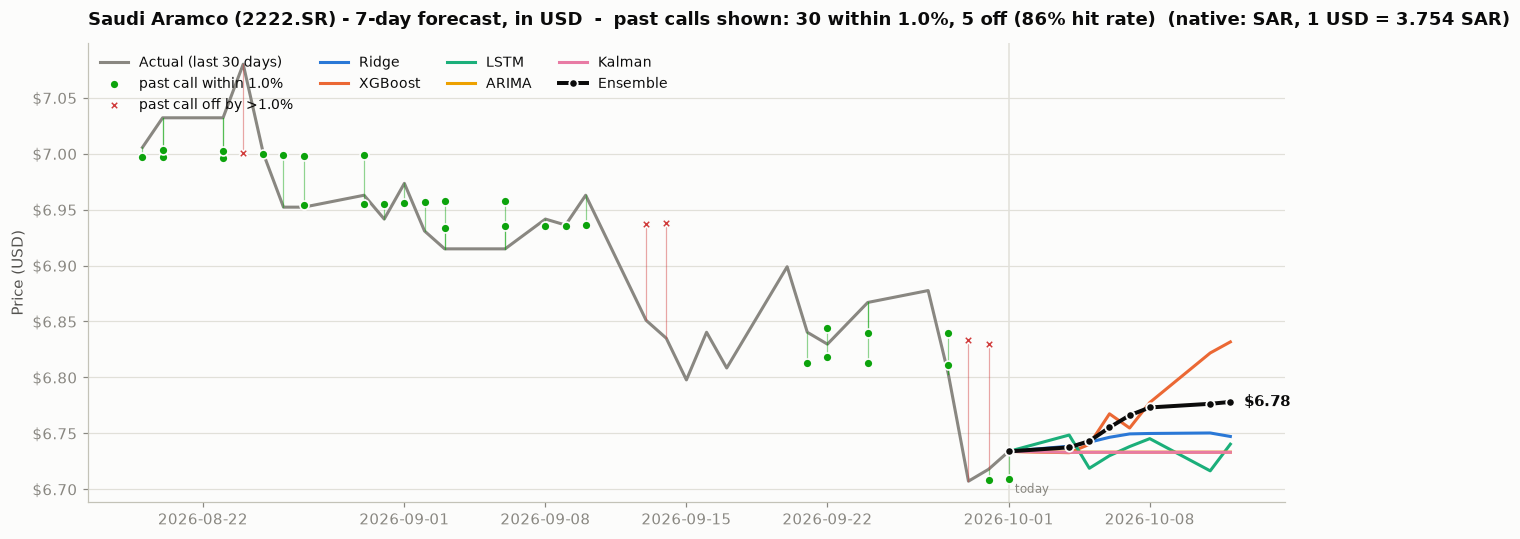


Predicted price by day, USD (native SAR: multiply by 3.754):
            Ridge  XGBoost  LSTM  ARIMA  Kalman  LASSO  RandomForest   DNN  WSAE-LSTM   TFT  Theta  N-BEATS  RegimeSwitch  ARIMAX  Ensemble  Fusion  Fusion-Top3
2026-10-04   6.74     6.73  6.75   6.73    6.73   6.73          6.74  6.81       6.72  6.79   6.73     6.73          6.73    6.73      6.74    6.74         6.74
2026-10-05   6.74     6.74  6.72   6.73    6.73   6.74          6.75  6.85       6.75  6.83   6.73     6.74          6.74    6.73      6.74    6.75         6.74
2026-10-06   6.75     6.77  6.73   6.73    6.73   6.74          6.77  6.90       6.73  6.84   6.73     6.74          6.74    6.73      6.76    6.75         6.75
2026-10-07   6.75     6.75  6.74   6.73    6.73   6.75          6.78  6.92       6.74  6.91   6.73     6.74          6.74    6.73      6.77    6.77         6.75
2026-10-08   6.75     6.78  6.75   6.73    6.73   6.75          6.79  6.94       6.74  6.86   6.74     6.73          6.74    6.73    

In [32]:
# Forecast Graph 2222 Sr -- shared code: raem_analysts/international/forecast_graph_2222_sr.py
use_shared("forecast_graph_2222_sr")

## 🔍 Decision Verifier / Fact-Check Agent — Post-Decision Recheck

In [ ]:
# Decision Verifier -- shared code: raem_analysts/international/decision_verifier.py
use_shared("decision_verifier")

## 📐 Position Sizing — rule-based vol-target + market-stress thermometer (v7) + gated RL (PPO) overlay

v7: size = min(MAX_WEIGHT, TARGET_VOL / vol) × market-stress multiplier, where vol = max(EWMA20, 60-day) and the stress multiplier comes from an equal-weight index of the other graph-panel stocks. HOLD can now trim a position that exceeds the cap. Switches: `USE_MARKET_STRESS`, `USE_RL_OVERLAY`, `RUN_SIZING_PRICE_BACKTEST`.


In [ ]:
# Position Sizing -- shared code: raem_analysts/international/position_sizing.py
use_shared("position_sizing")

## 📈 10-Day Scenario Estimate — if you buy today, what range of gain/loss could 10 trading days bring?

For every day in the last 12 months of daily closes: `10-day return % = (close 10 trading days later / close that day − 1) × 100`. The percentiles of those ~230 returns (worst 5% … best 5%) are applied to your buy price, with an assumed round-trip cost, and the chance of a gain is counted.

Set `SCEN_BUY_PRICE`, `SCEN_SHARES` and `SCEN_COST_PCT` at the top of the next cell. It is the **historical range** of outcomes, **not a forecast** and not investment advice. Skips quietly if the price fetch fails.

In [ ]:
# Scenario Estimate -- shared code: raem_analysts/international/scenario_estimate.py
use_shared("scenario_estimate")

## 💾 Save Episode to ChromaDB Memory

In [ ]:
# Save Episode -- shared code: raem_analysts/international/save_episode.py
use_shared("save_episode")

In [35]:
# Trading Log View -- shared code: raem_analysts/international/trading_log_view.py
use_shared("trading_log_view")

📦 Total sessions in file: 3
📅 Showing: 2026-10-03 (most recent)

Session start : 2026-10-03 16:15:59
Company       : 2222.SR
Total steps   : 16

⏰ 16:16:00 | 📌 LLM Setup
----------------------------------------------------------------------
📥 INPUT:
Ollama Qwen2.5 7B

📤 OUTPUT:
LLM initialized

⏰ 16:17:07 | 📌 Fundamentals Analyst
----------------------------------------------------------------------
📥 INPUT:
  [COMPANY]: 2222.SR
  [DATE]: 2026-10-03
  [TOOLS_USED]: get_fundamentals, get_balance_sheet, get_cashflow, get_income_statement

📤 OUTPUT:
  [METRICS]: {'market_cap': '$6115.42B', 'pe_ratio': '14.95858', 'eps_ttm': '1.69', 'revenue_ttm': '$1823.48B', 'beta': '0.006', 'dividend_yield': '5.37', '52w_high': '27.96', '52w_low': '23.29', '50d_sma': '26.1716', 'net_income_q': '$121.51B', 'gross_profit_q': 'N/A', 'operating_income_q': '$216.15B', 'ebitda_q': '$245.18B', 'free_cash_flow_q': '$45.98B', 'stock_buybacks_q': '$-2.03B', 'net_debt': '$126.32B', 'total_debt': '$355.24B'}
  [REP

In [36]:
# Comparison Backtest -- shared code: raem_analysts/international/comparison_backtest.py
use_shared("comparison_backtest")

✅ Loaded 3 sessions

📋 DAILY DECISION COMPARISON


'      Date Company Decision                                                                                                                  Summary\n2026-09-24 2222.SR     HOLD **Rating**: Hold  **Executive Summary**: Based on the comprehensive analysis and the final recommendation from the Funda\n2026-09-27 2222.SR     HOLD **Rating**: Hold  **Executive Summary**: Based on the comprehensive analysis and the provided data, the final decision f\n2026-10-03 2222.SR     HOLD **Rating**: Hold  **Executive Summary**: Based on the comprehensive analysis provided and considering the investor profi'


📈 TECHNICAL INDICATOR TRENDS


'      Date       RSI      MACD    50-SMA   Boll_UB   Boll_LB\n2026-09-24 41.249192 -0.147839 26.143661 26.335321 25.472679\n2026-09-27 49.758178 -0.116257 26.124843 26.291943 25.466057\n2026-10-03 36.659911 -0.204065 26.036078 26.269237 25.160763'


🏦 FUNDAMENTALS TRACKING


...


📰 NEWS SENTIMENT TREND


'      Date  Overall  Positive  Negative  Neutral\n2026-09-24 POSITIVE         3         0        2\n2026-09-27 POSITIVE         3         0        2\n2026-10-03 POSITIVE         1         2        2'


💰 SIMPLE BACKTEST — Follow-the-Signal Strategy


'      Date Signal  Price Action Portfolio\n2026-09-24   HOLD $25.64      —   $10,000\n2026-09-27   HOLD $25.92      —   $10,000\n2026-10-03   HOLD $25.28      —   $10,000'


  Starting Capital : $10,000
  Final Value      : $10,000
  Total Return     : +0.00%

🎯 DECISION CONSISTENCY
  HOLD   ███  (3/3 days — 100%)

✅ Analysis complete!


## 📈 7-Day Forecast & Hit Rate (standalone)

This section runs **on its own**: no Ollama and none of the agent cells above are needed. After a kernel restart you can run just the cell below.

It trains 14 base models:

- **Originals:** Ridge, XGBoost, LSTM, ARIMA, Kalman.
- **From the papers in `paper/`:** LASSO (Iworiso 2023), Random Forest and DNN (Krauss et al. 2016), WSAE-LSTM (Bao et al. 2017), N-BEATS (Oreshkin et al. 2020).
- **Also added:** regime switching, ARIMAX, a Temporal Fusion Transformer (TFT), and the Theta method.

On top of these sit two **fusion** models, which learn for this ticker how to combine the base models:

- **Fusion:** learned non-negative weights, with "no change" as one of the options.
- **Fusion-Top3:** the 3 lowest-error models, each weighted by 1/error.

The **Ensemble** is the average of the **best two** base models for this ticker, meaning the two with the lowest error on past holdout dates. The chart and the price table show the **top 10** base models.

**Fusion check table:** this is the fair comparison. Each pick (best two, fusion weights, top 3) is made on the earlier holdout dates. Then every model, the Ensemble, both fusions, the mean of all models and "no change" are scored on later dates that the picks never saw. A `mae_vs_naive` below 1 beats "no change".

Every run saves today's 7-day forecast to `forecast_log/`. It then grades every earlier forecast whose target date has arrived. The **hit rate** is measured two ways:

- **Within ±1%**: the predicted price landed within 1% of the actual close on that day.
- **Direction right**: the forecast said up or down from the price when it was made, and the price went that way. "No change" forecasts don't count either way.

A direction hit rate only means something if it beats **always predicting UP**, because stocks drift, so that baseline is shown next to it. The **p-value** says whether the day-7 calls beat a coin flip by more than luck; under 0.05 means they do. Past forecasts include walk-forward replays, each trained only on data available on that date.

  2222.SR: already current (last row 2026-10-01)
2222.SR (Saudi Aramco): 514 rows (514 snapshot + 0 daily-log), 2024-09-17 to 2026-10-01
  training 14 multi-step models on 458 labeled rows ...
Graded 0 past prediction(s) whose target date has now arrived.


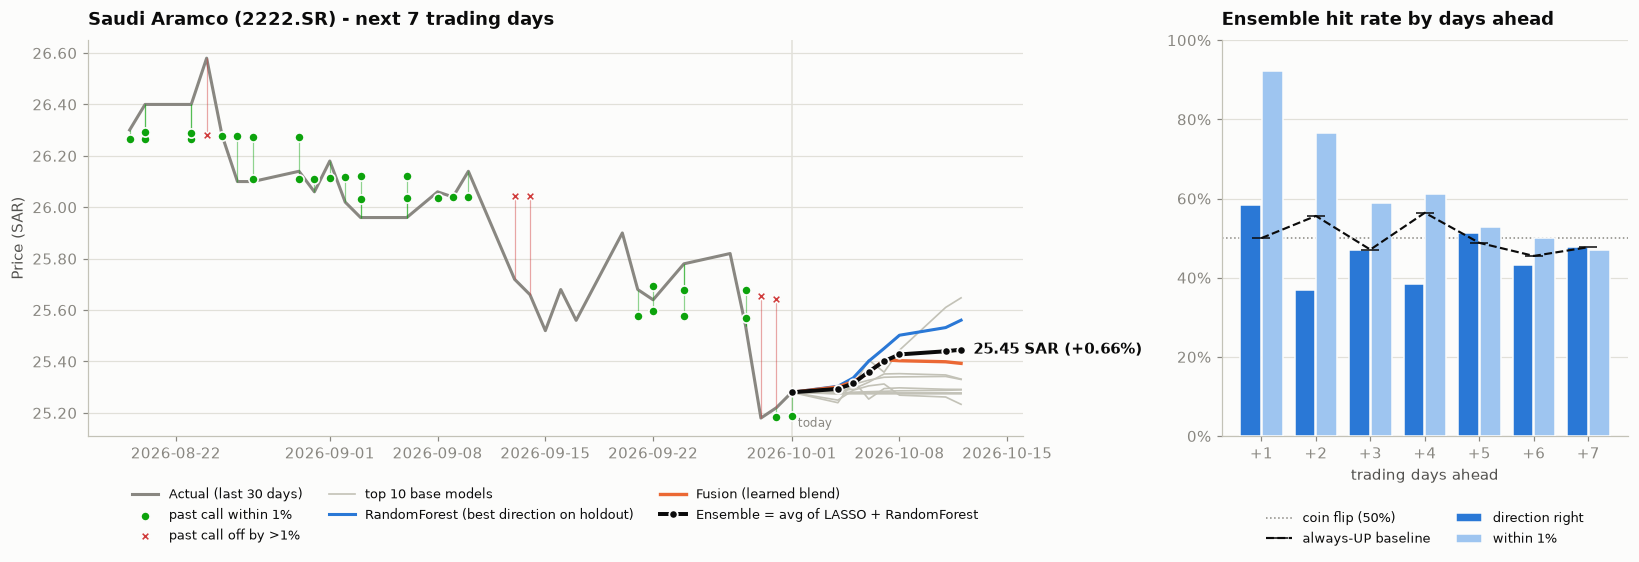

Ensemble = average of the best two models: LASSO + RandomForest
Predicted price (SAR) for the next 7 trading days -- Ensemble, fusions and the top 10 models:


,Ensemble,Fusion,Fusion-Top3,LASSO,RandomForest,ARIMAX,Kalman,ARIMA,Theta,Ridge,WSAE-LSTM,N-BEATS,XGBoost
date,,,,,,,,,,,,,
2026-10-04,25.29,25.30,25.29,25.28,25.30,25.27,25.28,25.28,25.28,25.30,25.24,25.25,25.28
2026-10-05,25.31,25.32,25.30,25.29,25.34,25.27,25.28,25.28,25.28,25.31,25.33,25.29,25.30
2026-10-06,25.36,25.36,25.33,25.32,25.40,25.27,25.28,25.28,25.28,25.33,25.25,25.31,25.41
2026-10-07,25.40,25.41,25.36,25.35,25.45,25.27,25.28,25.28,25.28,25.34,25.29,25.31,25.36
2026-10-08,25.43,25.40,25.38,25.35,25.50,25.27,25.28,25.28,25.29,25.34,25.30,25.27,25.44
2026-10-11,25.44,25.40,25.38,25.35,25.53,25.27,25.28,25.28,25.29,25.34,25.29,25.26,25.61
2026-10-12,25.45,25.39,25.39,25.33,25.56,25.27,25.28,25.28,25.29,25.33,25.29,25.23,25.65


Top 10 base models by error on the common holdout dates (mae_vs_naive < 1 beats 'no change'):


,holdout_mae,mae_vs_naive
model,,
LASSO,0.0081,0.9627
RandomForest,0.0082,0.9827
ARIMAX,0.0083,0.9923
Kalman,0.0083,0.9944
ARIMA,0.0083,0.9953
Theta,0.0084,0.9999
Ridge,0.0084,1.0015
WSAE-LSTM,0.0085,1.0108
N-BEATS,0.0087,1.0364


Holdout scoreboard -- every base model on the last 15% of history (mae_vs_naive < 1 beats 'no change'; always-UP would score 38.7% direction):


...

Ensemble, by days ahead:


,graded_calls,hit_within_1pct_%,mean_abs_error_%,direction_calls,direction_hit_%,always_up_%
days_ahead,,,,,,
1,51,92.2,0.55,12,58.3,50.0
2,51,76.5,0.73,27,37.0,55.6
3,51,58.8,0.99,34,47.1,47.1
4,49,61.2,1.03,39,38.5,56.4
5,51,52.9,1.32,43,51.2,48.8
6,50,50.0,1.47,44,43.2,45.5
7,51,47.1,1.52,44,47.7,47.7


Most recent graded Ensemble calls:


,made_on,target_date,days_ahead,price_then,predicted,actual,error_%,within_1pct,direction
0,2026-09-21,2026-09-22,1,25.68,25.70,25.64,0.22,HIT,wrong
1,2026-09-17,2026-09-22,3,25.56,25.60,25.64,0.17,HIT,right
2,2026-09-21,2026-09-24,3,25.68,25.68,25.78,0.39,HIT,flat call
3,2026-09-17,2026-09-24,5,25.56,25.58,25.78,0.79,HIT,right
4,2026-09-21,2026-09-28,5,25.68,25.68,25.54,0.53,HIT,flat call
5,2026-09-17,2026-09-28,7,25.56,25.57,25.54,0.12,HIT,flat call
6,2026-09-21,2026-09-29,6,25.68,25.65,25.18,1.88,miss,right
7,2026-09-29,2026-09-30,1,25.18,25.18,25.22,0.14,HIT,flat call
8,2026-09-21,2026-09-30,7,25.68,25.64,25.22,1.67,miss,right
9,2026-09-29,2026-10-01,2,25.18,25.19,25.28,0.37,HIT,flat call


149 call(s) still waiting for their target date (next one: 2026-10-04); 30 fell on a holiday or missing day and can never be graded.


In [37]:
# Forecast Hit Rate 2222 Sr -- shared code: raem_analysts/international/forecast_hit_rate_2222_sr.py
use_shared("forecast_hit_rate_2222_sr")

## 🔮🧐 7-Day Price Forecast Agent + Reviewer Agent (standalone)

Two code-only agents (no Ollama, no earlier cell needed) that sit on top of the 7-day models above and give one answer to *"what will the price be over the next 7 trading days?"*.

**Forecast agent** — takes every base model's error on the common out-of-sample holdout dates, picks the **3 best models for this ticker**, and averages their day+1 ... day+7 paths into one forecast.

**Reviewer agent** — audits that forecast. When a check fails it **changes the forecast** and says what it changed:

- **Data freshness** — warns if the last price is old (the forecast would start from a stale price).
- **Path integrity** — a member with NaN or non-positive prices is replaced by the next best model.
- **Members beat naive** — a member that does not beat "no change" on the holdout is swapped for a better one.
- **Direction agreement** — warns when the 3 models disagree on up/down.
- **Calibration** — if the average is over-confident on the holdout, every move is scaled toward "no change" (only if that cuts the holdout error by 2% or more).
- **Plausible range** — a move bigger than the 95th percentile of past same-horizon moves is clipped.
- **Price band** — a 10-90% range from the models' own holdout errors.
- **Live track record** — the graded hit rate from `forecast_log/`, for context.

The result is a day-by-day price table (the 3 members, the reviewed forecast, low/high), a chart, and a confidence label (HIGH / MEDIUM / LOW). During **Run All** it reuses the forecast trained earlier; run on its own it trains the models first (~2 min). The logic lives in `forecast_agent.py` in the project root.

This is a statistical forecast, not advice: the fusion check table above shows how little most models beat "no change", and LOW confidence means exactly that.

In [ ]:
# ================================================================
# 7-DAY FORECAST AGENT + REVIEWER AGENT -- standalone, run this cell on its own
# ================================================================
import os, sys, warnings
if os.path.abspath("..") not in sys.path:
    sys.path.insert(0, os.path.abspath(".."))

import predictor_lib as pl
import forecast_lib as fl
import forecast_agent as fa

# after the imports: statsmodels re-enables its own warnings when first imported
warnings.filterwarnings("ignore")

AGENT_TICKER = "2222.SR"

# During "Run All" the 7-DAY FORECAST GRAPH cell has already trained every model
# for this ticker -- reuse that instead of training twice.
if isinstance(globals().get("fcast"), dict) and fcast.get("ticker") == AGENT_TICKER:
    print("Reusing the forecast trained earlier in this run.")
else:
    pl.top_up_data_csv(AGENT_TICKER)               # adds finished trading days only
    fcast = fl.forecast_ticker(AGENT_TICKER)       # 14 base models, best-two Ensemble, 2 fusions (~2 min)
    fl.record_forecast(AGENT_TICKER, fcast)        # archived, graded on later runs
    fl.grade_forecasts(AGENT_TICKER)

agent_out = fa.run_forecast_and_review(fcast)      # forecast agent -> reviewer agent -> table + chart
